In [3]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, RocCurveDisplay
from src.preprocessing import get_preprocessor

train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

X_train, y_train = train.drop(columns=["Churn"]), train["Churn"]
X_test, y_test = test.drop(columns=["Churn"]), test["Churn"]

In [4]:
def make_pipeline(model):
    return Pipeline([
        ("preprocess", get_preprocessor(X_train)),
        ("model", model),
    ])

models = {
    "Logistic Regression": make_pipeline(LogisticRegression(max_iter=1000, random_state=42)),
    "Decision Tree (no limit)": make_pipeline(DecisionTreeClassifier(random_state=42)),
    "Decision Tree (depth 5)": make_pipeline(DecisionTreeClassifier(max_depth=5, random_state=42)),
    "Random Forest": make_pipeline(RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)),
    "XGBoost": make_pipeline(XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                                           eval_metric="logloss", random_state=42)),
}

In [6]:
rows = []

for name, pipe in models.items():
    pipe.fit(X_train, y_train)

    pred = pipe.predict(X_test)
    proba_test = pipe.predict_proba(X_test)[:, 1]
    proba_train = pipe.predict_proba(X_train)[:, 1]

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC (test)": roc_auc_score(y_test, proba_test),
        "ROC-AUC (train)": roc_auc_score(y_train, proba_train),
    })

results = pd.DataFrame(rows).set_index("Model").round(3)
results

,Accuracy,Precision,Recall,F1,ROC-AUC (test),ROC-AUC (train)
Model,,,,,,
Logistic Regression,0.804,0.654,0.556,0.601,0.842,0.849
Decision Tree (no limit),0.731,0.493,0.487,0.490,0.652,1.000
Decision Tree (depth 5),0.799,0.632,0.583,0.606,0.834,0.852
Random Forest,0.789,0.627,0.508,0.561,0.827,1.000
XGBoost,0.796,0.645,0.519,0.575,0.839,0.905


In [7]:
results["Train-test AUC gap"] = (results["ROC-AUC (train)"] - results["ROC-AUC (test)"]).round(3)
results.sort_values("ROC-AUC (test)", ascending=False)

,Accuracy,Precision,Recall,F1,ROC-AUC (test),ROC-AUC (train),Train-test AUC gap
Model,,,,,,,
Logistic Regression,0.804,0.654,0.556,0.601,0.842,0.849,0.007
XGBoost,0.796,0.645,0.519,0.575,0.839,0.905,0.066
Decision Tree (depth 5),0.799,0.632,0.583,0.606,0.834,0.852,0.018
Random Forest,0.789,0.627,0.508,0.561,0.827,1.000,0.173
Decision Tree (no limit),0.731,0.493,0.487,0.490,0.652,1.000,0.348


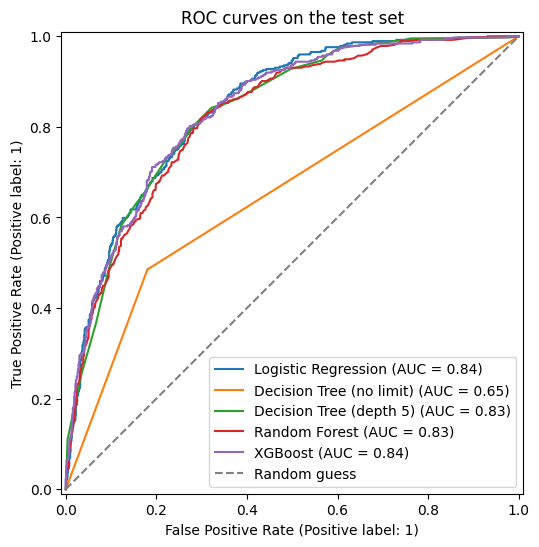

In [8]:
fig, ax = plt.subplots(figsize=(7, 6))

for name, pipe in models.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)

ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guess")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right")
plt.show()